# Pronóstico de ventas por SKU
## Parte 1: preparación de datos y análisis exploratorio

Objetivo: pronosticar los meses junio, julio y agosto de 2025 para los productos A, B, C, D y E.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Carga de datos

In [ ]:
CARPETA_DATOS = "../Datos"
skus = ["A", "B", "C", "D", "E"] # Stock Keeping Unit -> código para identificar los productos

datos = []
for s in skus:
    datos.append(pd.read_excel(f"{CARPETA_DATOS}/ventas_SKU_P{s}_hasta_mayo.xlsx"))

df = pd.concat(datos, ignore_index=True)
df["SKU"] = df["SKU"].str.replace("Producto", "")
df["Fecha"] = pd.to_datetime(df["Fecha"])
df

,Mes,SKU,VentasMensuales,year,Fecha,rubro,subrubro,tipo
0,1,A,34,2021,2021-01-01,HOGAR Y OBRA,OBRA,A
1,2,A,45,2021,2021-02-01,HOGAR Y OBRA,OBRA,A
2,3,A,58,2021,2021-03-01,HOGAR Y OBRA,OBRA,A
3,4,A,27,2021,2021-04-01,HOGAR Y OBRA,OBRA,A
4,5,A,54,2021,2021-05-01,HOGAR Y OBRA,OBRA,A
...,...,...,...,...,...,...,...,...
260,1,E,169,2025,2025-01-01,HOGAR Y OBRA,OBRA,A
261,2,E,160,2025,2025-02-01,HOGAR Y OBRA,OBRA,A
262,3,E,130,2025,2025-03-01,HOGAR Y OBRA,OBRA,A
263,4,E,139,2025,2025-04-01,HOGAR Y OBRA,OBRA,A


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Mes              265 non-null    int64         
 1   SKU              265 non-null    str           
 2   VentasMensuales  265 non-null    int64         
 3   year             265 non-null    int64         
 4   Fecha            265 non-null    datetime64[us]
 5   rubro            265 non-null    str           
 6   subrubro         265 non-null    str           
 7   tipo             265 non-null    str           
dtypes: datetime64[us](1), int64(3), str(4)
memory usage: 16.7 KB


In [4]:
print("Faltantes:", df.isna().sum().sum())
print("Duplicados:", df.duplicated(["SKU", "Fecha"]).sum())
print("Ventas <= 0:", (df["VentasMensuales"] <= 0).sum())

Faltantes: 0
Duplicados: 0
Ventas <= 0: 0


In [5]:
ventas = df.pivot(index="Fecha", columns="SKU", values="VentasMensuales")

meses = pd.date_range(ventas.index.min(), ventas.index.max(), freq="MS")
print("Meses en los datos:", len(ventas))
print("Meses esperados:", len(meses))
ventas.tail()

Meses en los datos: 53
Meses esperados: 53


SKU,A,B,C,D,E
Fecha,,,,,
2025-01-01,45,63,22,30,169
2025-02-01,33,49,16,59,160
2025-03-01,23,42,16,25,130
2025-04-01,42,61,27,66,139
2025-05-01,32,53,29,65,116


Los datos están completos: 53 meses por SKU (enero 2021 a mayo 2025), sin faltantes, duplicados ni ceros.

Los cinco productos tienen el mismo rubro, subrubro y tipo, así que esas columnas no sirven para agrupar.

## Evolución de las ventas

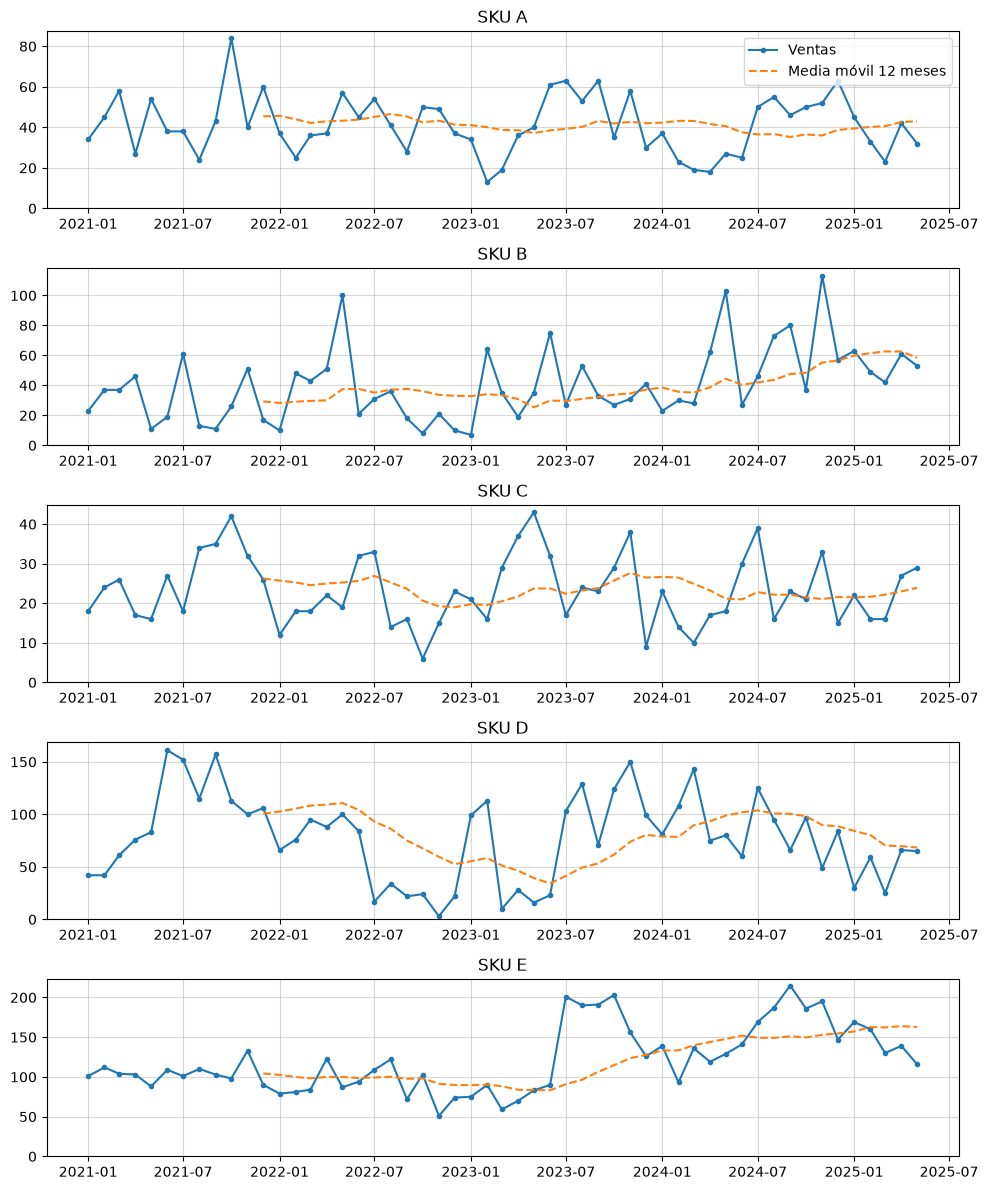

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12))

for i, s in enumerate(skus):
    axes[i].plot(ventas[s], marker="o", markersize=3, label="Ventas")
    axes[i].plot(ventas[s].rolling(12).mean(), linestyle="--", label="Media móvil 12 meses")
    axes[i].set_title(f"SKU {s}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.5)

axes[0].legend()
plt.tight_layout()
plt.show()

- A y C oscilan alrededor de un nivel estable
- B sube de nivel a partir de abril 2024
- D tiene un período muy bajo entre mediados de 2022 y mediados de 2023
- E pega un salto en julio 2023 y se mantiene más arriba

## Estadísticas descriptivas

In [7]:
resumen = ventas.describe().T
resumen["cv"] = resumen["std"] / resumen["mean"] # medimos la dispersion de los datos tmb
for sku in resumen.index:
    if resumen.loc[sku, "cv"] < 0.2:
        resumen.loc[sku, "variabilidad"] = "Baja"
    elif resumen.loc[sku, "cv"] < 0.5:
        resumen.loc[sku, "variabilidad"] = "Moderada"
    else:
        resumen.loc[sku, "variabilidad"] = "Alta"
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,cv,variabilidad
SKU,,,,,,,,,,
A,53.0,41.25,14.48,13.0,32.0,40.0,52.0,84.0,0.35,Moderada
B,53.0,40.43,24.47,7.0,23.0,36.0,53.0,113.0,0.61,Alta
C,53.0,23.21,8.74,6.0,16.0,22.0,29.0,43.0,0.38,Moderada
D,53.0,77.58,41.30,3.0,42.0,80.0,103.0,161.0,0.53,Alta
E,53.0,121.42,41.44,51.0,90.0,110.0,141.0,215.0,0.34,Moderada


In [8]:
ventas.groupby(ventas.index.year).mean().round(1)

SKU,A,B,C,D,E
Fecha,,,,,
2021,45.4,29.3,26.2,100.7,104.3
2022,41.3,33.1,19.0,52.6,89.9
2023,42.1,37.2,26.5,80.4,127.8
2024,38.8,56.6,21.6,88.6,154.7
2025,35.0,53.6,22.0,49.0,142.8


- Las escalas son muy distintas: C vende unas 23 unidades por mes y E unas 121.
- B (cv 0.61) y D (cv 0.53) son los más variables.
- A tener en cuenta: 2025 tiene solo enero a mayo, así que su promedio no es comparable directamente con los años completos.

**El SKU E tiene el mayor volumen y una variabilidad relativa baja, mientras que B y D parecen ser los casos más desafiantes.**

## Cambios de nivel

In [9]:
cortes = {"B": "2024-04-01", "E": "2023-07-01"}

for sku, fecha in cortes.items():
    antes = ventas.loc[ventas.index < fecha, sku].mean()
    despues = ventas.loc[ventas.index >= fecha, sku].mean()
    print(f"{sku}: antes de {fecha[:7]} = {antes:.1f}, después = {despues:.1f}")

B: antes de 2024-04 = 32.7, después = 61.9
E: antes de 2023-07 = 93.3, después = 158.1


In [10]:
d = ventas["D"]
bajo = (d.index >= "2022-07-01") & (d.index <= "2023-06-01")

print("D entre jul-2022 y jun-2023:", round(d[bajo].mean(), 1))
print("D resto del período:", round(d[~bajo].mean(), 1))
d[bajo]

D entre jul-2022 y jun-2023: 34.2
D resto del período: 90.3


Fecha
2022-07-01     17
2022-08-01     34
2022-09-01     22
2022-10-01     24
2022-11-01      3
2022-12-01     22
2023-01-01     99
2023-02-01    113
2023-03-01     10
2023-04-01     28
2023-05-01     16
2023-06-01     23
Name: D, dtype: int64

In [11]:
# Verificamos si cada SKU esta creciendo, dismiuyendo o constante
ultimos_12 = ventas.iloc[-12:].mean()
anteriores_12 = ventas.iloc[-24:-12].mean()
(ultimos_12 / anteriores_12).round(2)

SKU
A    1.06
B    1.32
C    1.13
D    0.69
E    1.10
dtype: float64

- B pasa de unas 33 a unas 62 unidades por mes desde mayo 2024
- E pasa de unas 93 a unas 158 desde julio 2023
- En D, entre julio 2022 y junio 2023 el promedio cae a 34 contra 90 del resto.
- D viene cayendo: los últimos 12 meses están un 31% abajo de los 12 anteriores.

Para B y E, la historia anterior al salto describe otro nivel. Un promedio de toda la serie los va a subestimar

## Estacionalidad

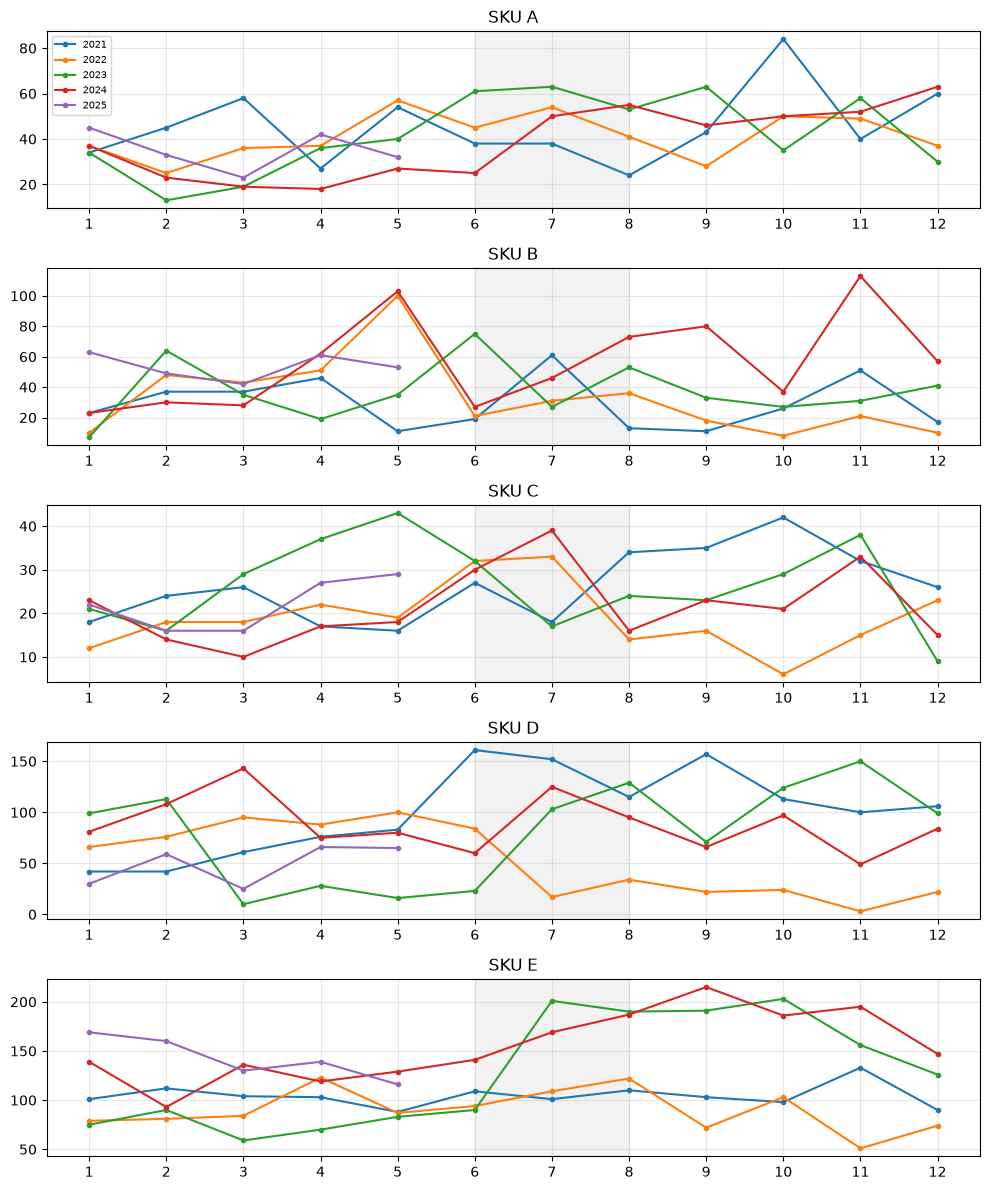

In [12]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12))

for i, sku in enumerate(skus):
    for anio in sorted(ventas.index.year.unique()):
        serie = ventas.loc[ventas.index.year == anio, sku]
        axes[i].plot(serie.index.month, serie.values, marker="o", markersize=3, label=anio)
    axes[i].axvspan(6, 8, alpha=0.1, color="gray")
    axes[i].set_title(f"SKU {sku}")
    axes[i].set_xticks(range(1, 13))
    axes[i].grid(alpha=0.3)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [13]:
# identificar el patrón estacional de cada SKU -> divido cada mes por la media móvil centrada de 12 meses
tendencia = ventas.rolling(12, center=True).mean()
relativo = ventas / tendencia

indice_mensual = relativo.groupby(relativo.index.month).mean().T
indice_mensual.round(2)

Fecha,1,2,3,4,5,6,7,8,9,10,11,12
SKU,,,,,,,,,,,,
A,0.90,0.50,0.59,0.72,1.01,1.05,1.23,1.04,1.07,1.33,1.20,1.15
B,0.36,1.41,0.98,1.08,1.98,1.09,1.14,1.04,0.78,0.62,1.25,0.69
C,0.82,0.67,0.80,1.08,1.14,1.41,1.22,0.92,1.03,1.03,1.26,0.76
D,1.44,1.53,0.91,0.81,0.85,0.80,1.13,1.12,0.90,1.07,0.82,0.94
E,0.87,0.81,0.79,0.90,0.82,0.89,1.21,1.26,1.15,1.19,1.05,0.89


- A parece tener un crecimiento en la segunda mitad del año

In [14]:
# Comparar el comportamiento del primer y segundo semestre
semestre = np.where(relativo.index.month <= 6, "1er sem", "2do sem")
por_semestre = relativo.groupby([relativo.index.year, semestre]).mean()
por_semestre.loc[2022:2024].round(2)

SKU               A     B     C     D     E
Fecha                                      
2022  1er sem  0.89  1.26  0.89  1.10  0.94
      2do sem  1.09  0.65  0.87  0.40  1.01
2023  1er sem  0.82  1.22  1.20  1.15  0.77
      2do sem  1.19  0.92  0.94  1.30  1.30
2024  1er sem  0.68  0.97  0.86  0.91  0.84
      2do sem  1.29  1.12  1.10  1.11  1.14

In [15]:
# Medir la similiutd del patrón mensual entre años -> ¿El patron de ventas de un SKU se parece entre los distintos años?
for s in skus:
    tabla = relativo[s].dropna().to_frame() # convertimos el sku en DataFrame
    tabla["anio"] = tabla.index.year
    tabla["mes"] = tabla.index.month
    perfiles = tabla.pivot(index="anio", columns="mes", values=s)
    corr = perfiles.T.corr().values # matriz simétrica con las correlaciones entre años
    promedio = corr[np.triu_indices(len(corr), 1)].mean()
    print(f"{s}: correlación promedio del perfil mensual entre años = {promedio:.2f}")

# Cercana a 1	Perfiles mensuales muy similares
# Cercana a 0	Poca relación entre perfiles
# Cercana a -1	Perfiles con comportamientos opuestos


A: correlación promedio del perfil mensual entre años = 0.13
B: correlación promedio del perfil mensual entre años = 0.06
C: correlación promedio del perfil mensual entre años = -0.08
D: correlación promedio del perfil mensual entre años = -0.18
E: correlación promedio del perfil mensual entre años = 0.16


In [16]:
# Ver si las ventas de junio, julio y agosto son mayores o menores que las del período enero-mayo
jun_ago = ventas[ventas.index.month.isin([6, 7, 8])]
ene_may = ventas[ventas.index.month <= 5]

ratio = jun_ago.groupby(jun_ago.index.year).mean() / ene_may.groupby(ene_may.index.year).mean()
ratio.round(2)

SKU,A,B,C,D,E
Fecha,,,,,
2021,0.76,1.01,1.30,2.35,1.05
2022,1.22,0.58,1.48,0.53,1.19
2023,2.08,1.61,0.83,1.60,2.13
2024,1.75,0.99,1.73,0.96,1.34
2025,NaN,NaN,NaN,NaN,NaN


- Mes a mes, el perfil casi no se repite entre años en ningún SKU (correlaciones entre -0.18 y 0.16). Con 4 años de datos, estimar 12 índices mensuales sería ajustar ruido.
- A nivel semestre sí aparece algo en A y E: en 2022, 2023 y 2024 el segundo semestre fue más alto que el primero. En A la diferencia es clara todos los años. En E es marcada en 2023 y 2024.
- En B, C y D no hay un patrón que se repita.

Para los modelos: probar estacionalidad en A y E, preferentemente simple (semestral o con pocos parámetros), y no forzarla en B, C y D. Hay que verificarlo en la validación.

## Autocorrelación

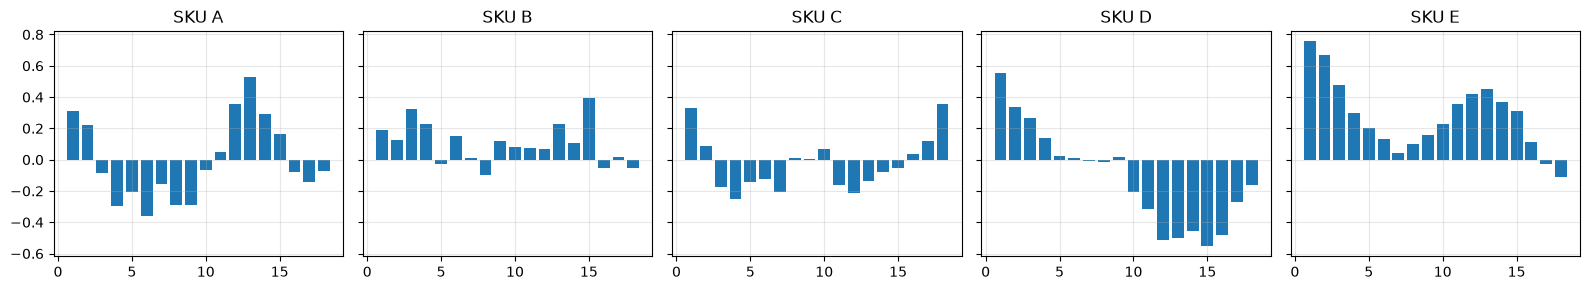

,A,B,C,D,E
1,0.31,0.19,0.33,0.55,0.76
2,0.22,0.13,0.09,0.34,0.67
3,-0.08,0.32,-0.17,0.27,0.48
6,-0.36,0.15,-0.12,0.01,0.13
12,0.36,0.07,-0.22,-0.52,0.42


In [28]:
# Relacion con las ventas de meses anteriores
rezagos = range(1, 19)
autocorr = pd.DataFrame({s: [ventas[s].autocorr(k) for k in rezagos] for s in skus}, index=rezagos)
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)

for i, s in enumerate(skus):
    axes[i].bar(autocorr.index, autocorr[s])
    axes[i].set_title(f"SKU {s}")
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

autocorr.loc[[1, 2, 3, 6, 12]].round(2)

- E es el SKU que muestra más claramente dependencia de sus ventas recientes.
- D también presenta persistencia de corto plazo, aunque con un comportamiento interanual muy diferente. 
- A tiene cierta señal interanual.
- B y C presentan patrones menos claros.

## Relación entre SKUs

In [ ]:
ventas.corr().round(2)

# Cercana a 1: ambos productos tienden a subir y bajar juntos.
# Cercana a -1: cuando uno sube, el otro tiende a bajar.
# Cercana a 0: no se observa una relación lineal clara.

SKU,A,B,C,D,E
SKU,,,,,
A,1.00,0.04,0.30,0.05,0.26
B,0.04,1.00,-0.03,-0.01,0.38
C,0.30,-0.03,1.00,0.07,0.04
D,0.05,-0.01,0.07,1.00,0.28
E,0.26,0.38,0.04,0.28,1.00


- Las correlaciones son bajas. No hay un comportamiento común entre los productos.
- No tenemos evidencia fuerte de que debamos utilizar las ventas de otros SKU como variables explicativas.

In [ ]:
ventas.diff().corr().round(2)

# diff(): calcula la diferencia entre cada mes y el anterior -> Delta Ventas_t = Ventas_t - Ventas_{t-1}
# Comparamos los cambiios mensuales de cada producto

SKU,A,B,C,D,E
SKU,,,,,
A,1.00,-0.02,0.18,0.06,-0.09
B,-0.02,1.00,-0.08,-0.06,0.02
C,0.18,-0.08,1.00,-0.11,0.01
D,0.06,-0.06,-0.11,1.00,0.22
E,-0.09,0.02,0.01,0.22,1.00


- No hay una relación fuerte entre las variaciones de los SKU como para justificar que las ventas de los otros productos esten relacionadas.

In [ ]:
# Compara la variabilidad individual de cada producto con la variabilidad de las ventas totales
total = ventas.sum(axis=1) # sumamos las ventas para cada mes
print("cv de cada SKU:")
print((ventas.std() / ventas.mean()).round(2))
print("cv del total:", round(total.std() / total.mean(), 2))

cv de cada SKU:
SKU
A    0.35
B    0.61
C    0.38
D    0.53
E    0.34
dtype: float64
cv del total: 0.27


- Los SKU tienen comportamientos independientes.
- Empezar con pronósitocs individuales -> no hay evidencia de que incorporar las ventas de otros productos mejore las predicciones
- E tiene una demanda sostenida
- B y D tienen mayor variabilidad -> más difíciles de pronosticar
- La demanda total es más estable que la de cada producto -> probar pronosticar las ventas totales

## Conclusiones

Por SKU:
- A: estable con indicios de mayores ventas en el segundo semestre.
Probar: media histórica o suavizado exponencial simple, con y sin ajuste semestral.
- B: muy variable, con salto de nivel en mayo 2024. 
Probar: suavizado exponencial simple (con más peso en las observaciones recientes) o media histórica de los meses posteriores al salto.
- C: ventas estables alrededor de 23 unidades. No hay estructura temporal clara. Baseline de media histórica, quizás sea difícil de superar.
- D: alta variabilidad, con un período atípico en 2022-2023 y una caída reciente.
Probar: suavizado exponencial simple o media histórica reciente. Va a tener mucha incertidumbre.
¿A qué se debió el comportamiento de 2022-2023?.
- E: hay un salto en julio 2023, en el segundo semestre se vende más y tiene memoria. 
Probar: Holt-Winters, suavizado exponencial simple y modelos con cambio de nivel.

Próximo paso: baselines (Naive, Seasonal Naive, media, media móvil) y luego modelos de suavizado exponencial, comparados con walk-forward validation:
- Ventana creciente, pronosticando 1, 2 y 3 meses adelante
- Puntos de corte desde diciembre 2022 hasta agosto 2024 (21 cortes, incluye junio-agosto 2024)
- Métricas: MAE, RMSE, MASE y sesgo. No uso MAPE porque D tiene meses con muy pocas unidades.

Preguntas para la empresa:
- ¿Hubo quiebres de stock en D entre 2022 y 2023?
- ¿Qué pasó con E en julio 2023 y con B en mayo 2024?
- ¿Hay promociones o cambios de precio planificados?
- ¿Cuál es el tiempo de reposición y el nivel de servicio buscado?